# Modelamiento descriptivo: análisis de clusters
## Data Mining - Doctorado UDP 2026
**Dr. Bastián González-Bustamante, Profesor Asociado** \
Octubre 2026

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Doctorado-UDP/data-mining-2026/blob/main/code/0_clustering.ipynb)

**Sesión de autoestudio · Demostración**

Hasta ahora, casi todos los modelos del curso fueron **predictivos**: aprenden a predecir una etiqueta conocida. El análisis de clusters es **descriptivo**: busca grupos en los datos **sin etiqueta**. Este notebook aplica k-means, el clustering jerárquico aglomerativo y DBSCAN, junto con la silueta y el análisis de componentes principales (PCA), a tres problemas:
- formas de juguete, para ver qué supone cada algoritmo;
- una **tipología de países** con indicadores de desarrollo (administración y políticas públicas);
- **perfiles diarios** de contaminación del aire en Pekín, como los perfiles de carga eléctrica (ingeniería).

Cada sección corresponde a tarjetas de la presentación:

| N.º | Sección | Presentación |
|---|---|---|
| 1 | Formas de juguete: qué supone cada algoritmo | Tipos de clusters; k-means; jerárquico; DBSCAN |
| 2 | Tipología de países: escalado, elección de *k*, perfiles, dendrograma, PCA, DBSCAN y validación | Todas las tarjetas de algoritmos y de evaluación; PCA |
| 3 | Perfiles diarios de PM2.5 | Caso de ingeniería |
| 4 | Ejercicios | No aplica |

**Cómo usarlo por su cuenta.**
1. Lean primero el capítulo 7 de Tan et al. (2019), "Cluster Analysis: Basic Concepts and Algorithms". Los autores lo ofrecen gratis en https://www-users.cse.umn.edu/~kumar001/dmbook/ch7_clustering.pdf. Para PCA, lean James et al. (2023), *ISLP*, disponible gratis en https://www.statlearning.com.
2. Revisen la presentación de la sesión **(pronto disponible)**.
3. Ejecuten este notebook de arriba abajo, leyendo las notas "Para recordar", y luego resuelvan los ejercicios.

Todo el notebook corre en la CPU de un computador portátil en menos de un minuto. Descarga siete archivos pequeños de Our World in Data y unos 8 MB del repositorio UCI. `random_state=86` en todos los pasos aleatorios.

### Entorno: local o Google Colab

Este notebook corre en su computador y en Google Colab. La primera celda de código detecta dónde se ejecuta:
- **En Google Colab** instala solo los paquetes que falten (en esta sesión, ninguno), sin actualizar los preinstalados, así que no hace falta reiniciar la sesión. Los datos se descargan de fuentes públicas. Para conservar sus cambios, use "Archivo → Guardar una copia en Drive".
- **En su computador** no instala nada: cree antes un entorno virtual con `pip install -r requirements.txt`.

Luego muestra las versiones instaladas y verifica que estén en el rango soportado: Python ≥ 3.11, scikit-learn ≥ 1.6, pandas ≥ 2.2, NumPy ≥ 2.0 y SciPy ≥ 1.11. Con versiones distintas de las de `requirements.txt`, algunos resultados pueden cambiar levemente.

In [1]:
## Entorno: detectar Google Colab, instalar solo lo que falte y verificar las versiones
import re
import sys
from importlib import invalidate_caches
from importlib.metadata import version
from importlib.util import find_spec

## Paquetes que usa este notebook: {módulo: (nombre en pip, versión mínima soportada)}
PAQUETES = {
    "sklearn": ("scikit-learn", "1.6"),
    "pandas": ("pandas", "2.2"),
    "numpy": ("numpy", "2.0"),
    "matplotlib": ("matplotlib", "3.9"),
    "scipy": ("scipy", "1.11"),
}

EN_COLAB = "google.colab" in sys.modules
faltan = [pip for modulo, (pip, _) in PAQUETES.items() if find_spec(modulo) is None]
if faltan and EN_COLAB:
    ## En Colab se instalan solo los paquetes que faltan; los preinstalados no se actualizan
    get_ipython().run_line_magic("pip", "install -q " + " ".join(faltan))
    invalidate_caches()
    faltan = []
## En su computador no se instala nada: el entorno virtual se crea con requirements.txt
assert not faltan, f"Faltan paquetes: {', '.join(faltan)}. Instálelos con pip install -r requirements.txt."


def version_al_menos(paquete, minima):
    ## Compara los dos primeros números de la versión instalada con la mínima (p. ej., "1.6.1" >= "1.6")
    actual = tuple(int(n) for n in re.findall(r"\d+", version(paquete))[:2])
    return actual >= tuple(int(n) for n in minima.split("."))


print(f"Python {sys.version.split()[0]} | "
      + " | ".join(f"{pip} {version(pip)}" for pip, _ in PAQUETES.values())
      + (" | Google Colab" if EN_COLAB else " | computador local"))
assert sys.version_info >= (3, 11), "Este notebook requiere Python 3.11 o superior."
antiguos = [f"{pip} {version(pip)} (mínimo {minima})" for pip, minima in PAQUETES.values()
            if not version_al_menos(pip, minima)]
assert not antiguos, f"Versiones no soportadas: {'; '.join(antiguos)}. Actualice esos paquetes en su entorno."

Python 3.12.7 | scikit-learn 1.9.1 | pandas 3.0.6 | numpy 2.5.4 | matplotlib 3.11.2 | scipy 1.18.1 | computador local


In [2]:
## Importar librerías necesarias
import io
import time
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, set_link_color_palette

import sklearn
from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

## Versiones (en su computador, las de requirements.txt; en Colab, las preinstaladas)
print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | scipy {scipy.__version__}")

pandas 3.0.6 | numpy 2.5.4 | scikit-learn 1.9.1 | scipy 1.18.1


In [3]:
## Estilo de los gráficos (el mismo de S8 a S12) y colores para hasta 6 clusters; gris para el ruido
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})
AZUL, NARANJA, VERDE, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
COLORES = np.array([AZUL, NARANJA, VERDE, "#9b59b6", "#d4a017", "#c0392b"])


def colores(etiquetas):
    ## Un color por cluster; las etiquetas -1 (ruido de DBSCAN) en gris claro
    etiquetas = np.asarray(etiquetas)
    return np.where(etiquetas < 0, "#cfcfcf", COLORES[np.clip(etiquetas, 0, None) % len(COLORES)])

## 1. Formas de juguete: qué supone cada algoritmo

Empezamos con datos simulados en dos dimensiones, para ver los grupos a simple vista. Como sabemos qué grupo generó cada punto, podemos medir cuánto se parece cada solución a la verdad con el **índice de Rand ajustado** (ARI; Hubert y Arabie, 1985), una versión del índice de Rand de Tan et al. (2019) corregida por azar. El ARI vale 1 si la solución coincide con los grupos verdaderos y cerca de 0 si el parecido no supera al azar. En un problema real no hay verdad conocida.

### 1.1 Dos lunas: clusters que no son esféricos

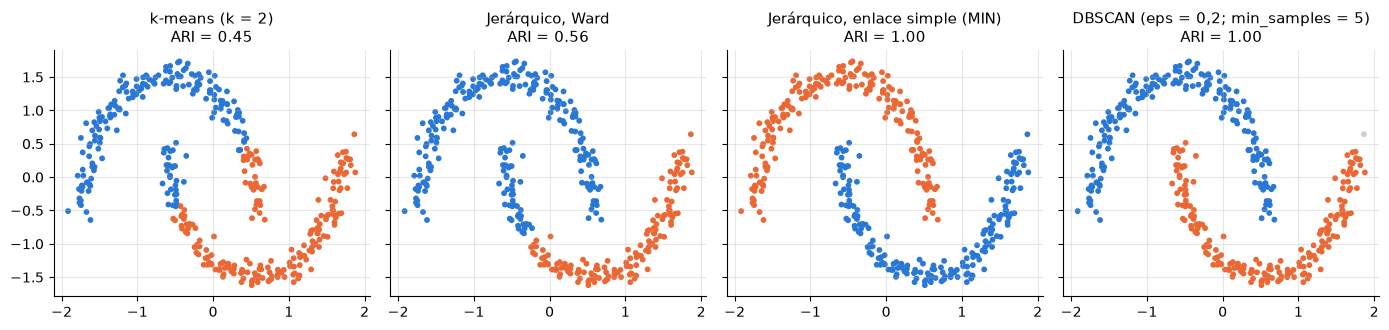

In [4]:
## Dos lunas entrelazadas: cuatro algoritmos sobre los mismos datos (escalados)
X_lunas, y_lunas = make_moons(n_samples=400, noise=0.06, random_state=86)
X_lunas = StandardScaler().fit_transform(X_lunas)

algoritmos = {
    "k-means (k = 2)": KMeans(n_clusters=2, n_init=10, random_state=86),
    "Jerárquico, Ward": AgglomerativeClustering(n_clusters=2, linkage="ward"),
    "Jerárquico, enlace simple (MIN)": AgglomerativeClustering(n_clusters=2, linkage="single"),
    "DBSCAN (eps = 0,2; min_samples = 5)": DBSCAN(eps=0.2, min_samples=5),
}
fig, ejes = plt.subplots(1, 4, figsize=(14, 3.4), sharex=True, sharey=True)
for ax, (nombre, modelo) in zip(ejes, algoritmos.items()):
    etiquetas = modelo.fit_predict(X_lunas)
    ax.scatter(X_lunas[:, 0], X_lunas[:, 1], c=colores(etiquetas), s=10)
    ax.set_title(f"{nombre}\nARI = {adjusted_rand_score(y_lunas, etiquetas):.2f}")
plt.tight_layout()
plt.show()

**Para recordar.**
- **k-means** asigna cada punto al centroide más cercano: supone clusters **compactos y más o menos esféricos**. Corta las lunas con una recta.
- **Ward** también minimiza la suma de cuadrados dentro de los grupos y se equivoca de forma parecida.
- El **enlace simple** une los grupos por sus puntos más cercanos y sigue la forma de cada luna. Su debilidad es el efecto "cadena": es sensible al ruido.
- **DBSCAN** define los clusters como regiones **densas** separadas por zonas poco densas, y también recupera las lunas. Los puntos que no pertenecen a ninguna región densa quedan como **ruido** (en gris).

### 1.2 Grupos de distinto tamaño y densidad

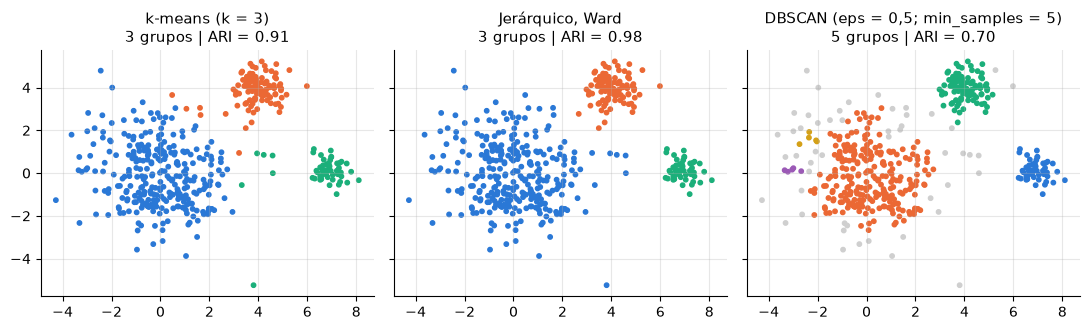

In [5]:
## Tres grupos: uno grande y disperso, uno mediano y uno pequeño y compacto
X_gotas, y_gotas = make_blobs(n_samples=[300, 100, 50], centers=[[0, 0], [4, 4], [7, 0]],
                              cluster_std=[1.5, 0.6, 0.4], random_state=86)
algoritmos = {
    "k-means (k = 3)": KMeans(n_clusters=3, n_init=10, random_state=86),
    "Jerárquico, Ward": AgglomerativeClustering(n_clusters=3, linkage="ward"),
    "DBSCAN (eps = 0,5; min_samples = 5)": DBSCAN(eps=0.5, min_samples=5),
}
fig, ejes = plt.subplots(1, 3, figsize=(11, 3.4), sharex=True, sharey=True)
for ax, (nombre, modelo) in zip(ejes, algoritmos.items()):
    etiquetas = modelo.fit_predict(X_gotas)
    n_grupos = len(set(etiquetas) - {-1})
    ax.scatter(X_gotas[:, 0], X_gotas[:, 1], c=colores(etiquetas), s=10)
    ax.set_title(f"{nombre}\n{n_grupos} grupos | ARI = {adjusted_rand_score(y_gotas, etiquetas):.2f}")
plt.tight_layout()
plt.show()

**Para recordar.**
- k-means y Ward recuperan bien los tres grupos, aunque k-means tiende a mover el borde del grupo grande hacia los pequeños: le cuesta trabajar con grupos de **tamaños** distintos.
- DBSCAN, con un solo `eps` para todo el espacio, no puede tratar a la vez el grupo disperso y los compactos: parte el grupo grande o lo deja como ruido. Le cuesta trabajar con **densidades** distintas.
- **No hay un algoritmo mejor en general.** Cada uno define "cluster" de otra manera. Antes de elegir, pregúntese qué tipo de grupo espera encontrar.

## 2. Tipología de países con indicadores de desarrollo

**Pregunta:** ¿hay "tipos" de países según su desarrollo económico, social y energético? Las tipologías de este tipo se usan en políticas públicas para comparar casos parecidos o focalizar programas.

**Datos:** siete indicadores de Our World in Data (OWID; licencia CC BY 4.0, que reúne fuentes como el Banco Mundial, Naciones Unidas y el Global Carbon Project), para **2023**, el año más reciente con los siete indicadores:

| Variable | Indicador (OWID) |
|---|---|
| `pib_pc` | PIB per cápita (PPA, dólares internacionales constantes) |
| `esperanza_vida` | Esperanza de vida al nacer (años) |
| `co2_pc` | Emisiones de CO₂ per cápita (toneladas) |
| `electricidad` | Población con acceso a electricidad (%) |
| `internet` | Población que usa internet (%) |
| `urbana` | Población urbana (%) |
| `fecundidad` | Hijos por mujer |

Los datos de OWID se actualizan periódicamente; con otra versión, las cifras pueden cambiar levemente.

In [6]:
## Descargar los indicadores de Our World in Data (un CSV público por indicador)
INDICADORES = {
    "pib_pc": "gdp-per-capita-worldbank",
    "esperanza_vida": "life-expectancy",
    "co2_pc": "co-emissions-per-capita",
    "electricidad": "share-of-the-population-with-access-to-electricity",
    "internet": "share-of-individuals-using-the-internet",
    "urbana": "share-of-population-urban",
    "fecundidad": "children-born-per-woman",
}
AÑO = 2023


def leer_url(url, intentos=3, timeout=60):
    ## Descarga con reintentos: un servidor lento a veces no responde a la primera
    for intento in range(1, intentos + 1):
        try:
            pedido = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(pedido, timeout=timeout) as respuesta:
                return respuesta.read()
        except OSError:
            if intento == intentos:
                raise
            time.sleep(5 * intento)


def descargar_owid(slug):
    url = f"https://ourworldindata.org/grapher/{slug}.csv?v=1&csvType=full&useColumnShortNames=true"
    datos = pd.read_csv(io.BytesIO(leer_url(url)))
    ## Solo países (código ISO de 3 letras); fuera los agregados de OWID (OWID_WRL, etc.)
    return datos[datos["code"].notna() & ~datos["code"].astype(str).str.startswith("OWID")]


inicio = time.perf_counter()
series, paises = [], None
for nombre, slug in INDICADORES.items():
    datos = descargar_owid(slug)
    valor = [c for c in datos.columns if c not in ("entity", "code", "year", "owid_region")][0]
    del_año = datos[datos["year"] == AÑO].set_index("code")
    series.append(del_año[valor].rename(nombre))
    if paises is None:  # nombres y regiones de OWID (vienen en el archivo del PIB)
        paises = del_año[["entity", "owid_region"]].rename(columns={"entity": "país", "owid_region": "región"})

paises_ind = pd.concat(series, axis=1).dropna()
paises = paises.reindex(paises_ind.index)
print(f"Descarga: {time.perf_counter() - inicio:.1f} s | {len(paises_ind)} países con los 7 indicadores en {AÑO}")
paises_ind.describe().round(1).T

Descarga: 1.9 s | 176 países con los 7 indicadores en 2023


,count,mean,std,min,25%,50%,75%,max
pib_pc,176.0,26784.8,26578.4,1033.0,6562.1,17069.0,40170.8,130296.8
esperanza_vida,176.0,73.4,7.2,54.5,67.4,74.4,78.8,85.5
co2_pc,176.0,4.5,5.6,0.1,0.9,3.1,5.6,40.1
electricidad,176.0,87.5,23.1,11.6,87.5,100.0,100.0,100.0
internet,176.0,71.2,25.5,7.2,58.5,81.6,90.7,100.0
urbana,176.0,62.0,22.0,15.1,44.2,63.4,78.9,100.0
fecundidad,176.0,2.4,1.3,0.7,1.5,1.9,3.2,6.1


**Preparación.**
- El PIB per cápita y el CO₂ per cápita son muy **asimétricos** (pocos países muy ricos o muy emisores). Usamos su **logaritmo en base 10**, para que las diferencias relativas (el doble, la mitad) pesen lo mismo en todo el rango.
- Luego **estandarizamos** cada variable (media 0, desviación estándar 1).

### 2.1 ¿Por qué estandarizar?

k-means usa distancias euclidianas, así que una variable con números grandes domina la distancia. Comparamos k-means con *k* = 3 sobre los datos originales y sobre los datos estandarizados.

In [7]:
## Transformar (log10 en las dos variables asimétricas) y estandarizar
paises_t = paises_ind.copy()
paises_t["pib_pc"] = np.log10(paises_t["pib_pc"])
paises_t["co2_pc"] = np.log10(paises_t["co2_pc"].clip(lower=0.01))
Z = StandardScaler().fit_transform(paises_t)

## k-means sobre los datos originales (sin transformar ni escalar) frente a los estandarizados
km_crudo = KMeans(n_clusters=3, n_init=20, random_state=86).fit(paises_ind)
km_est = KMeans(n_clusters=3, n_init=20, random_state=86).fit(Z)
varianzas = paises_ind.var()
print("Parte de la varianza total que aporta cada variable (datos originales):")
print((100 * varianzas / varianzas.sum()).map("{:.4f}%".format).to_string())
print(f"\nCoincidencia entre ambas soluciones (ARI): {adjusted_rand_score(km_crudo.labels_, km_est.labels_):.2f}")
print("PIB per cápita mediano por cluster, datos originales:",
      paises_ind.groupby(km_crudo.labels_)["pib_pc"].median().round(0).sort_values().tolist())

Parte de la varianza total que aporta cada variable (datos originales):
pib_pc            99.9998%
esperanza_vida     0.0000%
co2_pc             0.0000%
electricidad       0.0001%
internet           0.0001%
urbana             0.0001%
fecundidad         0.0000%

Coincidencia entre ambas soluciones (ARI): 0.22
PIB per cápita mediano por cluster, datos originales: [10245.0, 49312.0, 116159.0]


**Para recordar.**
- En los datos originales, el PIB per cápita (en dólares) aporta prácticamente toda la varianza. k-means termina cortando a los países por **una sola variable**: los grupos son tramos de ingreso.
- Tras transformar y estandarizar, todas las variables pesan. Las dos soluciones coinciden solo en parte.
- La estandarización es una **decisión del analista**, no un detalle técnico. James et al. (2023) la mencionan entre las decisiones pequeñas que cambian mucho el resultado.

### 2.2 ¿Cuántos clusters? El codo y la silueta

Probamos *k* = 2 a 8 con dos criterios:
- la **suma de cuadrados dentro de los clusters** (SSE, `inertia_` en scikit-learn), que siempre baja al aumentar *k*; se busca un **codo**;
- el **coeficiente de silueta** promedio: para cada punto compara la distancia media a su propio cluster (*a*) con la del cluster vecino más cercano (*b*), como (*b* − *a*) / max(*a*, *b*). Va de −1 a 1; más alto es mejor.

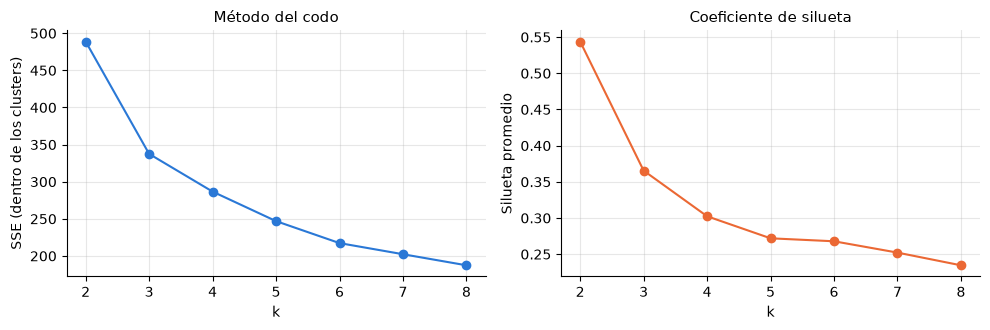

,SSE,silueta,tamaños
k,,,
2,488.875,0.544,"[130, 46]"
3,337.487,0.366,"[78, 61, 37]"
4,286.683,0.302,"[67, 59, 26, 24]"
5,246.916,0.272,"[53, 47, 31, 24, 21]"
6,217.321,0.268,"[49, 42, 26, 22, 19, 18]"
7,202.335,0.252,"[41, 39, 30, 23, 19, 18, 6]"
8,187.411,0.235,"[40, 35, 26, 19, 18, 18, 14, 6]"


In [8]:
## SSE y silueta para k = 2..8 (k-means con 20 inicializaciones)
filas = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=86).fit(Z)
    filas.append({"k": k, "SSE": km.inertia_, "silueta": silhouette_score(Z, km.labels_),
                  "tamaños": sorted(np.bincount(km.labels_).tolist(), reverse=True)})
eleccion_k = pd.DataFrame(filas).set_index("k")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
ax1.plot(eleccion_k.index, eleccion_k["SSE"], "o-", color=AZUL)
ax1.set(xlabel="k", ylabel="SSE (dentro de los clusters)", title="Método del codo")
ax2.plot(eleccion_k.index, eleccion_k["silueta"], "o-", color=NARANJA)
ax2.set(xlabel="k", ylabel="Silueta promedio", title="Coeficiente de silueta")
plt.tight_layout()
plt.show()
eleccion_k.round(3)

**Para recordar.**
- La silueta es más alta con *k* = 2 y baja de forma gradual. El codo de la SSE no es nítido.
- Los criterios **orientan**, pero no deciden solos. Con *k* = 2 solo se separa un grupo de países de menor desarrollo del resto. Con *k* = 3 aparece además un grupo intermedio, más útil para comparar casos. Usamos *k* = 3 y lo **validamos** en las secciones siguientes.
- Que la silueta sea máxima con *k* = 2 y luego baje sugiere que hay **una** separación clara (los países de menor desarrollo frente al resto) y que las demás divisiones cortan un continuo. Lo comprobamos con PCA y DBSCAN.

### 2.3 Perfiles de los tres tipos

Un cluster solo es útil si se puede **describir**. Mostramos la mediana de cada indicador por cluster (en sus unidades originales), el tamaño y algunos países. La silueta por cluster indica qué grupos están mejor definidos.

In [9]:
## k-means con k = 3: perfiles, tamaños, silueta por cluster y países de ejemplo
K = 3
km3 = KMeans(n_clusters=K, n_init=20, random_state=86).fit(Z)
## Renumerar los clusters por PIB per cápita mediano (0 = menor), para que los nombres sean estables
orden = paises_ind.groupby(km3.labels_)["pib_pc"].median().sort_values().index
renumerar = {viejo: nuevo for nuevo, viejo in enumerate(orden)}
tipo_km = np.array([renumerar[e] for e in km3.labels_])

perfiles = paises_ind.groupby(tipo_km).median()
perfiles.insert(0, "países", np.bincount(tipo_km))
perfiles.insert(1, "silueta", pd.Series(silhouette_samples(Z, tipo_km)).groupby(tipo_km).mean())
perfiles.index.name = "tipo"
display(perfiles.round(2))

latam = ["ARG", "BOL", "BRA", "CHL", "COL", "ECU", "MEX", "PER", "PRY", "URY", "VEN", "HTI", "GTM", "HND"]
for tipo in range(K):
    ejemplos = paises.loc[paises_ind.index[tipo_km == tipo], "país"]
    en_latam = paises.loc[[c for c in latam if c in paises_ind.index and tipo_km[paises_ind.index.get_loc(c)] == tipo], "país"]
    print(f"Tipo {tipo} ({len(ejemplos)} países). Ejemplos: {', '.join(ejemplos.sample(6, random_state=86))}"
          f"\n   América Latina: {', '.join(en_latam) if len(en_latam) else '(ninguno)'}")

,países,silueta,pib_pc,esperanza_vida,co2_pc,electricidad,internet,urbana,fecundidad
tipo,,,,,,,,,
0,37,0.45,2939.12,63.65,0.27,51.1,28.71,39.29,4.19
1,61,0.22,12476.60,71.79,2.14,99.6,74.12,58.31,2.25
2,78,0.44,42720.51,79.93,5.63,100.0,91.48,79.31,1.48


Tipo 0 (37 países). Ejemplos: Liberia, Zimbabwe, Haiti, Mali, Chad, Mozambique
   América Latina: Haiti
Tipo 1 (61 países). Ejemplos: Nauru, Moldova, Sri Lanka, Mauritius, Mongolia, Saint Vincent and the Grenadines
   América Latina: Bolivia, Ecuador, Paraguay, Guatemala, Honduras
Tipo 2 (78 países). Ejemplos: Italy, North Macedonia, Belgium, Macao, Palau, Cyprus
   América Latina: Argentina, Brazil, Chile, Colombia, Mexico, Peru, Uruguay


**Para recordar.**
- Los tres tipos se ordenan por nivel de desarrollo: el tipo 0 tiene menos ingreso, menos acceso a electricidad e internet y más fecundidad; el tipo 2, lo contrario; el tipo 1 queda en medio.
- Los nombres ("menor", "intermedio", "mayor desarrollo") los pone el analista después de mirar los perfiles. El algoritmo solo entrega números.
- La silueta por cluster muestra que no todos los tipos están igual de bien definidos: los países del medio están más cerca de los otros grupos.

### 2.4 Clustering jerárquico: dendrograma y tipos de enlace

El clustering **aglomerativo** parte con cada país como un cluster y une, paso a paso, los dos clusters más cercanos. El **dendrograma** registra esas uniones: la **altura** a la que se unen dos ramas indica cuán distintos son. Cortarlo a una altura da una partición. Usamos el método de **Ward** (SciPy) y mostramos solo las 30 últimas uniones: un número entre paréntesis indica cuántos países hay bajo esa rama, y un número sin paréntesis es un país individual (su posición en la tabla).

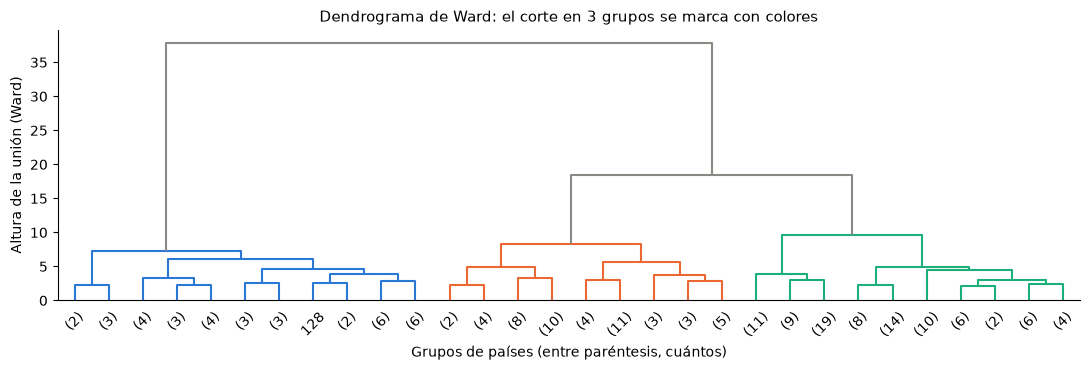

Coincidencia entre k-means y Ward con 3 grupos (ARI): 0.77


,grupo más grande,segundo,tercero
ward,89,50,37
complete,128,33,15
average,93,46,37
single,174,1,1


In [10]:
## Dendrograma de Ward (últimas 30 uniones) y corte en 3 grupos
uniones = linkage(Z, method="ward")
set_link_color_palette([AZUL, NARANJA, VERDE])
fig, ax = plt.subplots(figsize=(11, 3.8))
dendrogram(uniones, truncate_mode="lastp", p=30, ax=ax, color_threshold=uniones[-(K - 1), 2],
           above_threshold_color=GRIS)
ax.set(xlabel="Grupos de países (entre paréntesis, cuántos)", ylabel="Altura de la unión (Ward)",
       title="Dendrograma de Ward: el corte en 3 grupos se marca con colores")
ax.grid(False)
plt.tight_layout()
plt.show()

tipo_ward = fcluster(uniones, t=K, criterion="maxclust")
print(f"Coincidencia entre k-means y Ward con 3 grupos (ARI): {adjusted_rand_score(tipo_km, tipo_ward):.2f}")

## Tamaño de los 3 grupos según el tipo de enlace
tamaños = {}
for metodo in ["ward", "complete", "average", "single"]:
    etiquetas = AgglomerativeClustering(n_clusters=K, linkage=metodo).fit_predict(Z)
    tamaños[metodo] = sorted(np.bincount(etiquetas).tolist(), reverse=True)
pd.DataFrame(tamaños, index=["grupo más grande", "segundo", "tercero"]).T

**Para recordar.**
- k-means y Ward llegan a tipologías parecidas, pero no idénticas: una clasificación que cambia al cambiar el algoritmo debe interpretarse con cautela.
- El **enlace simple** (MIN) produce un grupo enorme y grupos de uno o dos países: el efecto "cadena". El **completo** (MAX) y el **promedio** quedan entre ambos extremos. El tipo de enlace es otra decisión del analista.
- En el dendrograma, la cercanía horizontal de dos hojas no significa nada; lo que importa es la **altura** a la que se unen (James et al., 2023).

### 2.5 PCA: ver los países en dos dimensiones

Con siete variables no podemos mirar los clusters directamente. El **análisis de componentes principales** (PCA) busca las direcciones en que los datos varían más. La primera componente es la combinación de variables con mayor varianza; la segunda, la de mayor varianza entre las perpendiculares a la primera. Proyectar sobre ellas permite dibujar los datos y ver qué variables los ordenan (las **cargas**).

Proporción de varianza explicada (PVE) por componente: [0.796 0.084 0.044 0.035 0.02  0.011 0.01 ]


,CP1,CP2
pib_pc,0.40,0.03
esperanza_vida,0.38,-0.09
co2_pc,0.39,-0.03
electricidad,0.37,-0.32
internet,0.41,0.04
urbana,0.31,0.88
fecundidad,-0.38,0.34


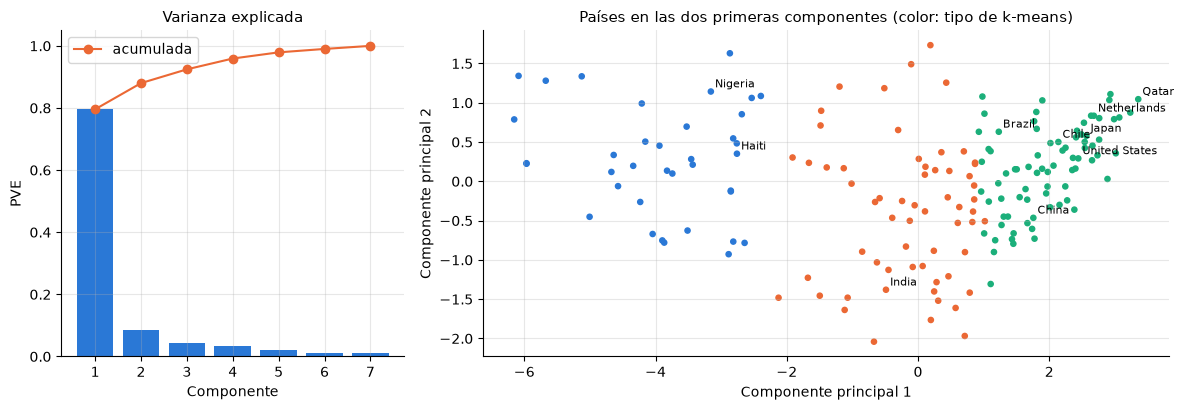

In [11]:
## PCA sobre los datos estandarizados: varianza explicada y cargas
pca = PCA(random_state=86).fit(Z)
puntajes = pca.transform(Z)
print("Proporción de varianza explicada (PVE) por componente:", pca.explained_variance_ratio_.round(3))
cargas = pd.DataFrame(pca.components_[:2].T, index=paises_t.columns, columns=["CP1", "CP2"])
display(cargas.round(2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 2]})
ax1.bar(range(1, 8), pca.explained_variance_ratio_, color=AZUL)
ax1.plot(range(1, 8), np.cumsum(pca.explained_variance_ratio_), "o-", color=NARANJA, label="acumulada")
ax1.set(xlabel="Componente", ylabel="PVE", title="Varianza explicada")
ax1.legend()
ax2.scatter(puntajes[:, 0], puntajes[:, 1], c=colores(tipo_km), s=14)
for codigo in ["CHL", "USA", "CHN", "IND", "NGA", "NLD", "BRA", "QAT", "HTI", "JPN"]:
    if codigo in paises_ind.index:
        i = paises_ind.index.get_loc(codigo)
        ax2.annotate(paises.loc[codigo, "país"], puntajes[i, :2], fontsize=8, xytext=(3, 3), textcoords="offset points")
ax2.set(xlabel="Componente principal 1", ylabel="Componente principal 2",
        title="Países en las dos primeras componentes (color: tipo de k-means)")
plt.tight_layout()
plt.show()

**Para recordar.**
- La primera componente explica la mayor parte de la varianza y carga casi por igual en todos los indicadores, con signo contrario en la fecundidad: es un eje de **desarrollo**. La segunda recoge sobre todo la **urbanización**.
- En el gráfico, el tipo 0 se separa del resto a lo largo de la primera componente, con una zona casi vacía entre medio. Los tipos 1 y 2, en cambio, son **franjas contiguas**: el límite entre ellos corta un continuo. Es útil para resumir, pero no prueba que existan "tipos naturales" de países.
- PCA sirve para **visualizar** y para **reducir** la dimensión antes de agrupar. No es un método de clustering: no asigna grupos.

### 2.6 DBSCAN: ¿hay regiones densas separadas?

DBSCAN necesita dos parámetros: `eps` (el radio de la vecindad) y `min_samples` (cuántos puntos debe tener la vecindad para que un punto sea **central**). Para elegir `eps` se ordenan las distancias de cada punto a su *k*-ésimo vecino más cercano y se busca el punto donde la curva sube con fuerza (Tan et al., 2019). El DBSCAN original usaba *k* = 4, que Tan et al. consideran razonable para datos en **dos** dimensiones; con siete variables usamos `min_samples = 5` (en scikit-learn incluye al propio punto), es decir, el cuarto vecino sin contar al propio punto.

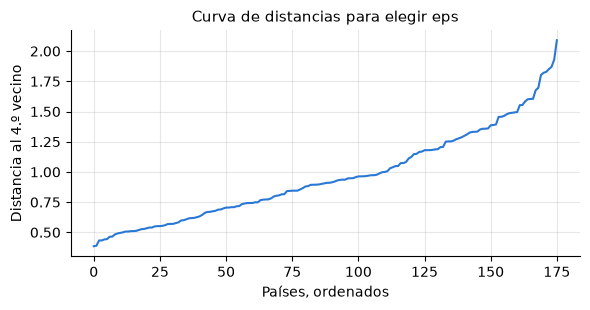

,eps,clusters,tamaños,ruido
0,1.00,2,"[119, 12]",45
1,1.25,2,"[126, 26]",24
2,1.50,2,"[168, 5]",3


tipo de k-means,0,1,2
DBSCAN,,,
-1,15,9,0
0,0,48,78
1,22,4,0


In [12]:
## Curva de distancias al 4.º vecino más cercano (ordenadas) para elegir eps
distancias, _ = NearestNeighbors(n_neighbors=5).fit(Z).kneighbors(Z)
d4 = np.sort(distancias[:, 4])  # columna 0 = el propio punto
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(d4, color=AZUL)
ax.set(xlabel="Países, ordenados", ylabel="Distancia al 4.º vecino", title="Curva de distancias para elegir eps")
plt.tight_layout()
plt.show()

filas = []
for eps in [1.0, 1.25, 1.5]:
    etiquetas = DBSCAN(eps=eps, min_samples=5).fit_predict(Z)
    ruido = paises.loc[paises_ind.index[etiquetas == -1], "país"]
    filas.append({"eps": eps, "clusters": len(set(etiquetas) - {-1}),
                  "tamaños": sorted(np.bincount(etiquetas[etiquetas >= 0]).tolist(), reverse=True),
                  "ruido": len(ruido)})
display(pd.DataFrame(filas))

## Composición con eps = 1,25: clusters de DBSCAN (−1 = ruido) frente a los tipos de k-means
etiquetas_db = DBSCAN(eps=1.25, min_samples=5).fit_predict(Z)
composicion = pd.crosstab(etiquetas_db, tipo_km, rownames=["DBSCAN"], colnames=["tipo de k-means"])
composicion

**Para recordar.**
- Con `eps` entre 1,0 y 1,25, DBSCAN encuentra **dos** regiones densas. Una grande reúne los tipos 1 y 2 de k-means: entre ellos no hay una zona poco densa que los separe. Otra, más pequeña, reúne parte del tipo 0.
- El resto del tipo 0 queda como **ruido**. "Ruido" no significa error: en DBSCAN es un punto en una región **poco densa**. Aquí indica que los países de menor desarrollo son más **heterogéneos** entre sí.
- Con `eps` = 1,5 casi todo se une en un solo cluster: el resultado depende mucho de `eps`.
- DBSCAN y PCA cuentan la misma historia: hay una separación clara y un continuo. Tan et al. (2019) llaman a esta pregunta la **tendencia al clustering**: antes de buscar clusters, conviene preguntarse si los datos los tienen.

### 2.7 Validación: ¿coinciden los tipos con las regiones?

Cuando existe una clasificación externa, se puede comparar con ella usando medidas **supervisadas** de validez, como el ARI. Comparamos la tipología con las **regiones** de OWID. No esperamos que coincidan: la pregunta es si los tipos son algo más que "continentes".

In [13]:
## Tabla de contingencia: tipo de k-means frente a región de OWID
tabla = pd.crosstab(paises["región"], tipo_km, margins=True, margins_name="Total")
tabla.columns = [f"tipo {c}" if c != "Total" else c for c in tabla.columns]
print(f"ARI entre los tipos y las regiones: {adjusted_rand_score(paises['región'], tipo_km):.2f}")
tabla

ARI entre los tipos y las regiones: 0.26


,tipo 0,tipo 1,tipo 2,Total
región,,,,
Africa,33,16,0,49
Asia,1,19,22,42
Europe,0,1,40,41
North America,1,14,7,22
Oceania,2,6,3,11
South America,0,5,6,11
Total,37,61,78,176


**Para recordar.**
- La tipología **no** reproduce los continentes (ARI bajo), pero tampoco es independiente de ellos: casi todo el tipo de menor desarrollo está en África, y Europa está casi entera en el tipo de mayor desarrollo.
- Las medidas supervisadas sirven cuando hay una referencia externa; las no supervisadas (SSE, silueta) evalúan la estructura interna. Las dos se complementan.
- Un clustering se **valida** también con conocimiento del dominio: ¿los tipos tienen sentido para quien conoce los casos? ¿Son estables si cambian los indicadores, el año o el algoritmo? (ejercicios 1 y 2).

## 3. Perfiles diarios de contaminación del aire (ingeniería)

En ingeniería es común agrupar **curvas**: perfiles de carga eléctrica, de demanda de agua o de tráfico. Cada día es un vector de 24 valores, uno por hora, y el clustering encuentra "días típicos". Lo aplicamos a la concentración horaria de PM2.5 en la estación Dongsi de Pekín (2013–2017), el mismo conjunto de datos UCI de la Sesión 10 (Chen, 2017).

In [14]:
## Descargar el ZIP de UCI y leer una estación (todo en memoria; como en S10, con reintentos)
URL_AIRE = "https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality+data.zip"


def leer_estacion(estacion="Dongsi", url=URL_AIRE):
    externo = zipfile.ZipFile(io.BytesIO(leer_url(url, timeout=120)))
    interno = zipfile.ZipFile(io.BytesIO(externo.read("PRSA2017_Data_20130301-20170228.zip")))
    nombre = f"PRSA_Data_20130301-20170228/PRSA_Data_{estacion}_20130301-20170228.csv"
    return pd.read_csv(io.BytesIO(interno.read(nombre)))


inicio = time.perf_counter()
aire = leer_estacion("Dongsi")
aire["fecha"] = pd.to_datetime(aire[["year", "month", "day"]])
perfiles_pm = aire.pivot_table(index="fecha", columns="hour", values="PM2.5")
completos = perfiles_pm.dropna()
print(f"Descarga: {time.perf_counter() - inicio:.1f} s | {len(perfiles_pm):,} días; "
      f"{len(completos):,} con las 24 horas medidas (usamos estos)")

## La forma del día: cada hora dividida por el promedio de ese día (1 = el promedio diario)
nivel_diario = completos.mean(axis=1)
forma = completos.div(nivel_diario, axis=0)

Descarga: 5.0 s | 1,456 días; 1,263 con las 24 horas medidas (usamos estos)


**Decisión de preparación.** Si agrupáramos las concentraciones tal como vienen, los clusters separarían sobre todo días **limpios** de días **contaminados**. Para encontrar **formas** de día (¿cuándo sube y baja la contaminación?), dividimos cada hora por el promedio de su día. Es la misma decisión que se toma con los perfiles de carga eléctrica: el nivel y la forma se analizan por separado.

,SSE,silueta
k,,
2,7049.501,0.359
3,5576.523,0.261
4,4884.843,0.255
5,4437.562,0.181
6,4039.901,0.195


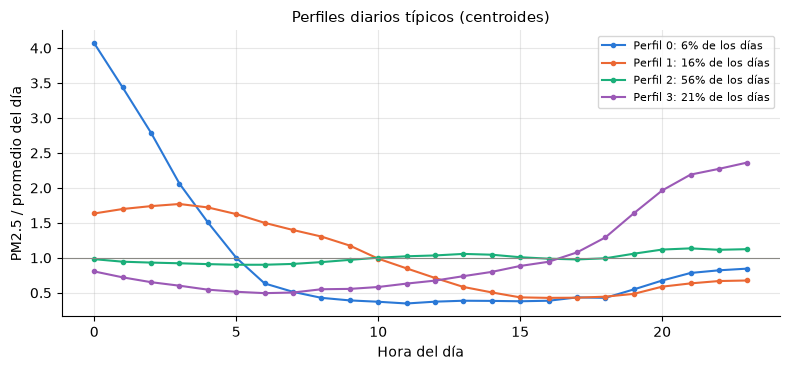

col_0,primavera,verano,otoño,invierno,"PM2.5 promedio del día (mediana, µg/m³)"
perfil,,,,,
0,0.04,0.06,0.08,0.09,40.0
1,0.19,0.16,0.12,0.18,71.0
2,0.61,0.65,0.58,0.41,86.0
3,0.16,0.13,0.23,0.33,33.0


In [15]:
## Elegir k y describir los perfiles típicos (k-means sobre la forma del día)
filas = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=20, random_state=86).fit(forma)
    filas.append({"k": k, "SSE": km.inertia_, "silueta": silhouette_score(forma, km.labels_)})
display(pd.DataFrame(filas).set_index("k").round(3))

K_PM = 4
km_pm = KMeans(n_clusters=K_PM, n_init=20, random_state=86).fit(forma)
## Renumerar por la hora del máximo del centroide, para que el orden sea estable
orden = np.argsort(np.argmax(km_pm.cluster_centers_, axis=1))
renumerar = {viejo: nuevo for nuevo, viejo in enumerate(orden)}
tipo_dia = np.array([renumerar[e] for e in km_pm.labels_])
centroides = km_pm.cluster_centers_[orden]

fig, ax = plt.subplots(figsize=(8, 3.8))
for t in range(K_PM):
    ax.plot(range(24), centroides[t], "o-", ms=3, color=COLORES[t],
            label=f"Perfil {t}: {np.mean(tipo_dia == t):.0%} de los días")
ax.axhline(1, color=GRIS, lw=0.8)
ax.set(xlabel="Hora del día", ylabel="PM2.5 / promedio del día", title="Perfiles diarios típicos (centroides)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

estacion = completos.index.month.map({12: "invierno", 1: "invierno", 2: "invierno", 3: "primavera", 4: "primavera",
                                      5: "primavera", 6: "verano", 7: "verano", 8: "verano",
                                      9: "otoño", 10: "otoño", 11: "otoño"})
resumen = pd.crosstab(tipo_dia, estacion, normalize="columns")[["primavera", "verano", "otoño", "invierno"]]
resumen["PM2.5 promedio del día (mediana, µg/m³)"] = nivel_diario.groupby(tipo_dia).median().round(0)
resumen.index.name = "perfil"
resumen.round(2)

**Para recordar.**
- Los centroides son **curvas** interpretables: días muy contaminados de madrugada que se limpian (perfil 0), días que bajan desde la mañana (perfil 1), días casi planos (perfil 2) y días en que la contaminación se acumula hacia la noche (perfil 3).
- Los perfiles se interpretan junto con variables externas. El perfil plano es el más frecuente y también el de **mayor nivel**: los episodios de contaminación persistente duran todo el día. La acumulación nocturna es más frecuente en otoño e invierno y ocurre en días de nivel bajo.
- La silueta es baja para todo *k*: los días cambian de forma gradual, como los países en la sección 2. De nuevo, *k* se elige por utilidad y se valida.
- Con perfiles de carga eléctrica el procedimiento es el mismo: normalizar, agrupar, interpretar los centroides y usar los perfiles típicos para planificar o diseñar tarifas.

## 4. Ejercicios

1. **Estabilidad de la tipología.** Repitan las secciones 2.2 y 2.3 con el año 2018 (cambie `AÑO`) o quitando un indicador. Comparen las nuevas etiquetas con las de 2023 usando el ARI (sobre los países presentes en ambos casos). ¿Son estables los tipos?
2. **Remuestreo.** Ajusten k-means con *k* = 3 sobre 20 submuestras del 80% de los países y calculen el ARI de cada una con la solución completa (en los países de la submuestra). ¿Qué tipos o países cambian más?
3. **DBSCAN sobre las componentes principales.** Apliquen DBSCAN a las dos primeras componentes de la sección 2.5. ¿Cambia la conclusión de la sección 2.6? Prueben varios `eps` guiándose por la curva de distancias.
4. **Otra estación.** Repitan la sección 3 con otra estación de Pekín (por ejemplo, `"Huairou"`, más rural) y comparen los perfiles típicos y su frecuencia.

In [16]:
## Plantilla para el ejercicio 2: descomente y complete
# rng = np.random.default_rng(86)
# ari = []
# for _ in range(20):
#     idx = rng.choice(len(Z), size=int(0.8 * len(Z)), replace=False)
#     sub = KMeans(n_clusters=3, n_init=20, random_state=86).fit_predict(Z[idx])
#     ari.append(adjusted_rand_score(tipo_km[idx], sub))
# print(np.round(ari, 2), round(np.mean(ari), 2))

**Para recordar (síntesis de la sesión).**
- El análisis de clusters busca grupos **sin etiqueta**. Cada algoritmo define "grupo" de otra manera: centroides (k-means), uniones sucesivas (jerárquico) o regiones densas (DBSCAN).
- Los resultados dependen de **decisiones del analista**: variables, transformaciones, escalado, algoritmo, enlace y número de clusters. Hay que justificarlas e informarlas.
- Los criterios internos (SSE, silueta) y externos (ARI) orientan la elección; la **interpretación** de los perfiles y la **estabilidad** la validan.
- Un clustering siempre entrega grupos, aunque los datos no los tengan: PCA y DBSCAN ayudan a ver si hay estructura o un continuo.

**Referencias**
- Arthur, D. y Vassilvitskii, S. (2007). k-means++: The advantages of careful seeding. *Proceedings of the Eighteenth Annual ACM-SIAM Symposium on Discrete Algorithms*, 1027–1035.
- Chen, S. (2017). *Beijing Multi-Site Air Quality* [conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5RK5G
- Ester, M., Kriegel, H.-P., Sander, J. y Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. *Proceedings of the Second International Conference on Knowledge Discovery and Data Mining (KDD-96)*, 226–231.
- Hubert, L. y Arabie, P. (1985). Comparing partitions. *Journal of Classification*, 2(1), 193–218.
- James, G., Witten, D., Hastie, T., Tibshirani, R. y Taylor, J. (2023). *An Introduction to Statistical Learning with Applications in Python*. Springer. Cap. 12.
- Our World in Data (2026). Indicadores de PIB per cápita, esperanza de vida, emisiones de CO₂, acceso a electricidad, uso de internet, población urbana y fecundidad. https://ourworldindata.org (CC BY 4.0).
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics*, 20, 53–65.
- Tan, P.-N., Steinbach, M., Karpatne, A. y Kumar, V. (2019). *Introduction to Data Mining* (2.ª ed.). Pearson. Cap. 7.